# 03 Data inspection (real skulls, synthetic faces)
Sample counts, missingness distributions, point density, bounding boxes, unit verification, duplicate and leakage checks. The checks come from
`validate_dataset`, which recomputes them from files on disk; the plots and the leakage check below are recomputed here too.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
from src.data import dataset as ds
rep = json.load(open(REAL + '/dataset_report.json'))
c = rep['counts']
print('independent base geometries:', c['independent_base_geometries'], '| observations:', c['observations'])
print('bases per split       :', c['base_per_split']); print('observations per split:', c['observations_per_split'])
print('all integrity checks passed:', rep['all_checks_passed'])
for k, v in rep['checks'].items(): print(f"  {k:32s}", v if not isinstance(v, dict) else v.get('passed'))

independent base geometries: 60 | observations: 480
bases per split       : {'calibration': 6, 'test': 6, 'train': 42, 'validation': 6}
observations per split: {'calibration': 48, 'test': 48, 'train': 336, 'validation': 48}
all integrity checks passed: True
  all_severity_bins_respected      True
  correspondence_consistent        True
  face_clears_bone                 True
  face_width_plausible             True
  files_present                    True
  leakage                          True
  no_exact_duplicate_skulls        True
  no_near_duplicate_skulls         True
  provenance_flags_present         True
  units_plausible_mm               True


In [3]:
recs = {s: ds.read_records(REAL, s) for s in ['train', 'validation', 'calibration', 'test']}
bases = {s: {r['base_id'] for r in rr} for s, rr in recs.items()}
pairs = [(a, b) for a in bases for b in bases if a < b]
print('split leakage (shared base geometries between splits):', {f'{a}/{b}': len(bases[a] & bases[b]) for a, b in pairs})
assert all(len(bases[a] & bases[b]) == 0 for a, b in pairs)

split leakage (shared base geometries between splits): {'train/validation': 0, 'calibration/train': 0, 'calibration/validation': 0, 'calibration/test': 0, 'test/train': 0, 'test/validation': 0}


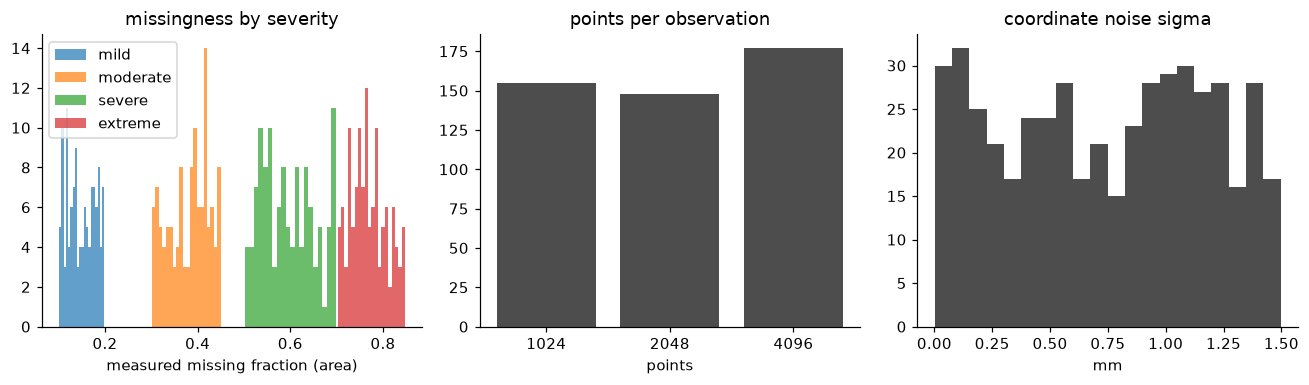

measured missingness (mean area fraction): {'extreme': 0.769, 'mild': 0.149, 'moderate': 0.381, 'severe': 0.597}
occlusion patterns: {'cap': 98, 'lateral': 83, 'patchy': 89, 'region': 105, 'upper': 105}


In [4]:
allr = [r for rr in recs.values() for r in rr]
sev = ['mild', 'moderate', 'severe', 'extreme']
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for s in sev:
    ax[0].hist([r['observation']['measured_missing_fraction'] for r in allr if r['observation']['severity'] == s], bins=20, alpha=.7, label=s)
ax[0].set_xlabel('measured missing fraction (area)'); ax[0].set_title('missingness by severity'); ax[0].legend()
npts = [r['observation']['n_points'] for r in allr]; u, k = np.unique(npts, return_counts=True)
ax[1].bar([str(x) for x in u], k, color='0.3'); ax[1].set_title('points per observation'); ax[1].set_xlabel('points')
ax[2].hist([r['observation']['noise_sigma_mm'] for r in allr], bins=20, color='0.3'); ax[2].set_title('coordinate noise sigma'); ax[2].set_xlabel('mm')
plt.tight_layout(); plt.show()
print('measured missingness (mean area fraction):', {k: round(v['measured_mean'], 3) for k, v in rep['missingness'].items()})
print('occlusion patterns:', rep['patterns'])

In [5]:
bb = rep['bounding_box_mm']
print('skull extent (mm)  min', np.round(bb['skull_extent_min'], 0), ' max', np.round(bb['skull_extent_max'], 0))
print('face  extent (mm)  min', np.round(bb['face_extent_min'], 0), ' max', np.round(bb['face_extent_max'], 0))
print('units plausible:', rep['checks']['units_plausible_mm'], '| face never inside bone:', rep['checks']['face_clears_bone'], rep['face_bone_penetration'])
print('duplicates: min pairwise skull Chamfer (mm) =', round(rep['duplicates']['min_pairwise_skull_chamfer_mm'], 2),
      '| exact duplicates absent:', rep['checks']['no_exact_duplicate_skulls'], '| near duplicates absent:', rep['checks']['no_near_duplicate_skulls'])

skull extent (mm)  min [131. 176. 186.]  max [161. 211. 256.]
face  extent (mm)  min [142.  83. 167.]  max [169. 132. 193.]
units plausible: True | face never inside bone: True {'mean_frac_over_1mm': 0.0, 'mean_mm': 0.0, 'p99_mm': 0.0, 'worst_max_mm': 0.0}
duplicates: min pairwise skull Chamfer (mm) = 5.54 | exact duplicates absent: True | near duplicates absent: True


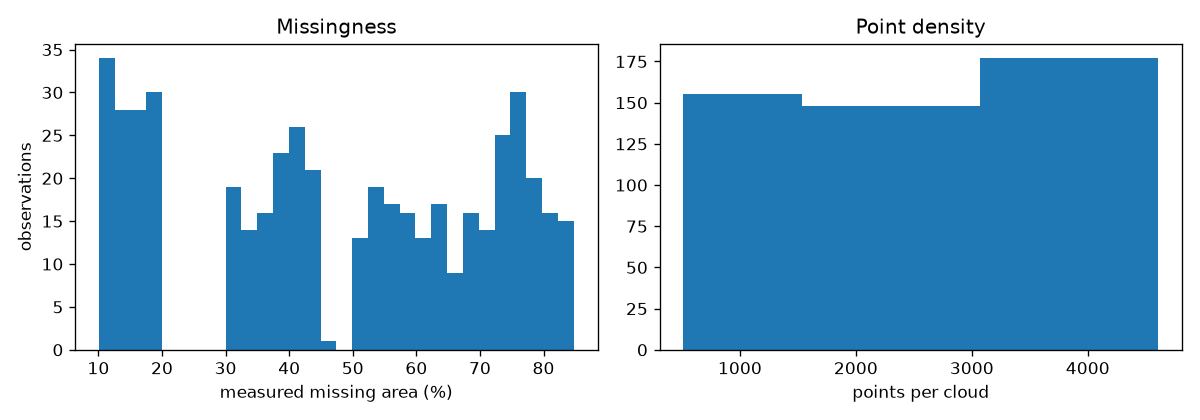

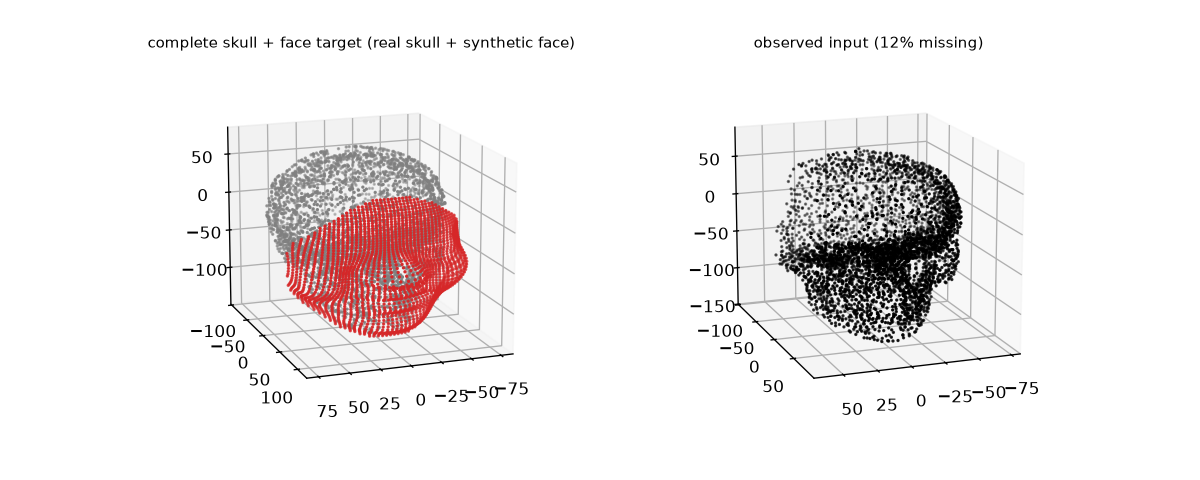

In [6]:
from IPython.display import Image, display
for f in ['missingness_density.png', 'example_sample.png']: display(Image(REAL + '/visualizations/' + f))